# Chapter 02: Model Evaluation, Classification Metrics, Error Analysis & Overfitting Prevention

**Assalam-o-Alaikum!** Chapter 01 mein aap ne apna pehla **Regression Model** (`student_marks_model.pkl`) train, evaluate, save, aur deploy karna seekha.  
Ab **Chapter 02** mein hum AI Engineering ka sab se ahem hissa seekhenge: **Ek AI Model ko sahi paimane (Metrics) par kaise parakhte hain, us ki ghaltiyon (False Positives vs False Negatives) ka tajziya kaise karte hain, aur Overfitting ko kaise rokte hain!**

### Is Chapter Ke 10 Core Goals
1. **Why Accuracy Alone Can Be Dangerous:** Imbalanced data par sirf Accuracy dekhne ka khatra (**Accuracy Paradox**).
2. **Confusion Matrix (`TP, TN, FP, FN`):** Classification ki 4 bunyadi terms ko asaan Pakistani misal se samajhna.
3. **Precision, Recall & F1-Score:** Kab **Precision** ahem hai (Spam Filter) aur kab **Recall** ahem hai (Customer Churn / Medical Disease).
4. **Probability Threshold Tuning (`0.50` vs `0.35`) & ROC-AUC:** Business zaroorat ke mutabiq decision threshold badalna.
5. **Underfitting vs Overfitting Detection:** Train Score vs Test Score ka muqabla kar ke **Overfitting** pakarna.
6. **Project 2 — Customer Churn Prediction:** Telecom customers (`datasets/customer_churn.xlsx`) par complete classification pipeline banana.
7. **Overfitting Experiment:** Unpruned Decision Tree (`max_depth=None`) vs Pruned Tree (`max_depth=3`) vs `RandomForestClassifier`.
8. **Row-by-Row Error Analysis:** Un test rows ko nikalna jahan model ne ghalti ki aur samajhna ke kyun ghalti hui.
9. **Save & Load Production Churn Pipeline:** `models/churn_pipeline.pkl` save kar ke naye customer ka Churn Risk `%` nikalna.
10. **Hands-On Exercise (Email Spam Classifier):** `datasets/email_spam.xlsx` par khud Spam Detection model banana!

## Part 1: Why Accuracy Alone Is Not Enough & The Confusion Matrix

### 1. The Accuracy Trap (Sirf Accuracy Par Bharosa Kyun Nahi Karna Chahiye?)
Socho aap **Jazz, Zong, ya PTCL** mein AI Engineer hain:
- Aap ke paas `100` customers ka data hai jin mein se **`90` customers company ke saath khush hain (`churned = 0`)** aur sirf **`10` customers company chhor kar ja rahe hain (`churned = 1`)**.
- Agar aap ek aisa be-kaar model banayein jo **har customer ke liye bina soche `0` (Stay) predict kar de**, toh:
  $$	ext{Accuracy} = rac{90}{100} = 90\%$$
- Dekhne mein `90% Accuracy` bohot shandar lagti hai, magar **us model ne `10` jane wale customers mein se `0` pakre!** Company ko 100% nuqsan ho gaya!
- **Golden Rule of AI Engineering:** Kabhi bhi kisi model ko sirf high training accuracy ya raw accuracy dekh kar reliable na maanein!

### 2. Confusion Matrix Ki 4 Deewarein (`TN`, `FP`, `FN`, `TP`)
Jab hum `confusion_matrix(y_test, predict_data)` chalate hain, toh Scikit-learn hamein $2 	imes 2$ table deta hai:

```text
                        PREDICTED BY AI MODEL
                      Predicted: 0 (Stay)     Predicted: 1 (Churn)
                   +-----------------------+-----------------------+
Actual: 0 (Stay)   |  True Negative (TN)   |  False Positive (FP)  |
                   |  (Sahi kaha: Rukega)  |  (Ghalti: False Alarm)|
                   +-----------------------+-----------------------+
Actual: 1 (Churn)  |  False Negative (FN)  |  True Positive (TP)   |
                   |  (Khatarnak Miss!)    |  (Sahi Pakra: Churn!) |
                   +-----------------------+-----------------------+
```

### 3. Precision, Recall, Aur F1-Score Ka Asaan Matlab (Hand-Calculated Example)
Maan lein Test Set ke `20` customers par Confusion Matrix yeh aaya:
- $	ext{TN} = 11$ (Asal mein ruke, model ne bhi `0` kaha)
- $	ext{FP} = 1$ (Asal mein ruka, model ne ghalti se `1` keh diya — **False Alarm**)
- $	ext{FN} = 2$ (Asal mein chhor gaye, model ne ghalti se `0` keh diya — **Missed Churn**)
- $	ext{TP} = 6$ (Asal mein chhor gaye, model ne sahi `1` pakra!)

Ab charon formulas haath se lagayein:
1. **Accuracy (Kul kitne sahi huye?):**
   $$	ext{Accuracy} = rac{TP + TN}{TP + TN + FP + FN} = rac{6 + 11}{20} = rac{17}{20} = 85.0\%$$
2. **Precision (Jinko model ne `1` kaha, un mein se asal mein kitne `1` nikle?):**
   $$	ext{Precision} = rac{TP}{TP + FP} = rac{6}{6 + 1} = rac{6}{7} = 85.7\%$$
   *Kab sab se ahem hai?* **Email Spam Detection** mein (taake koi zaroori official email ghalti se Spam folder `FP` mein na chali jaye!).
3. **Recall / Sensitivity (Asal mein jitne `1` they, model ne un mein se kitne pakre?):**
   $$	ext{Recall} = rac{TP}{TP + FN} = rac{6}{6 + 2} = rac{6}{8} = 75.0\%$$
   *Kab sab se ahem hai?* **Customer Churn, Fraud Detection, aur Cancer Screening** mein (taake koi jane wala customer ya bimar mareez `FN` miss na ho!).
4. **F1-Score (Precision aur Recall ka Balanced Harmonic Mean):**
   $$	ext{F1-Score} = 2 	imes rac{	ext{Precision} 	imes 	ext{Recall}}{	ext{Precision} + 	ext{Recall}} = 2 	imes rac{0.857 	imes 0.750}{0.857 + 0.750} = 80.0\%$$

## Part 2: Step-by-Step Implementation (DotZohaib Simple Code Format)

Ab hum **[DotZohaib/Data-Science-Course](https://github.com/DotZohaib/Data-Science-Course)** ke [28_Confusion_Matrix_data_science.ipynb](https://github.com/DotZohaib/Data-Science-Course/blob/main/28_Confusion_Matrix_data_science.ipynb) aur [confusion_matrix_analysis.py](https://github.com/DotZohaib/Data-Science-Course/blob/main/confusion_matrix_analysis.py) ke exact simple cell structure mein **Project: Telecom Customer Churn Prediction** banayenge!

### Step 1 — Import Required Libraries

In [1]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)

### Line-by-Line Explanation of Imports
- `LogisticRegression`, `DecisionTreeClassifier`, `RandomForestClassifier`: Hamare 3 classification models jin ka hum muqabla karenge.
- `confusion_matrix`, `classification_report`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score`, `roc_auc_score`: Classification model ko har zawiye se parakhne ke paimane.

### Step 2 — Load `customer_churn.xlsx` Dataset (With Synthetic Fallback)

In [2]:
if not os.path.exists("datasets/customer_churn.xlsx"):
    os.makedirs("datasets", exist_ok=True)
    rng = np.random.RandomState(42)
    n = 100
    ten = rng.randint(1, 60, n)
    bil = np.round(rng.uniform(1200, 6500, n), 0)
    cal = rng.randint(0, 9, n)
    gb = np.round(rng.uniform(5.0, 80.0, n), 1)
    con = rng.choice([1, 12, 24], size=n, p=[0.45, 0.35, 0.20])
    lgt = -1.2 - 0.06*ten + 0.0004*bil + 0.48*cal - 0.015*gb - 0.08*con + rng.normal(0, 0.85, n)
    ch = (1.0 / (1.0 + np.exp(-lgt)) >= 0.5).astype(int)
    pd.DataFrame({
        "customer_id": np.arange(1001, 1001 + n),
        "tenure_months": ten,
        "monthly_bill_pkr": bil,
        "support_calls": cal,
        "data_gb_used": gb,
        "contract_months": con,
        "churned": ch,
    }).to_excel("datasets/customer_churn.xlsx", index=False)

database = pd.read_excel("datasets/customer_churn.xlsx")
database.head(5)

,customer_id,tenure_months,monthly_bill_pkr,support_calls,data_gb_used,contract_months,churned
0,1001,39,5676,5,71.3,12,0
1,1002,52,5161,7,61.1,12,0
2,1003,29,4060,4,76.5,1,0
3,1004,15,4310,3,29.8,24,0
4,1005,43,6316,1,46.5,24,0


### Step 3 — Inspect Shape, Missing Values & Class Distribution (`value_counts`)
Classification shuru karne se pehle hamesha dekhein ke target column (`churned`) mein `0` aur `1` ki tadad kitni hai:

In [3]:
database.shape

(100, 7)

In [4]:
database.isnull().sum()

customer_id         0
tenure_months       0
monthly_bill_pkr    0
support_calls       0
data_gb_used        0
contract_months     0
churned             0
dtype: int64

In [5]:
database["churned"].value_counts()

churned
0    73
1    27
Name: count, dtype: int64

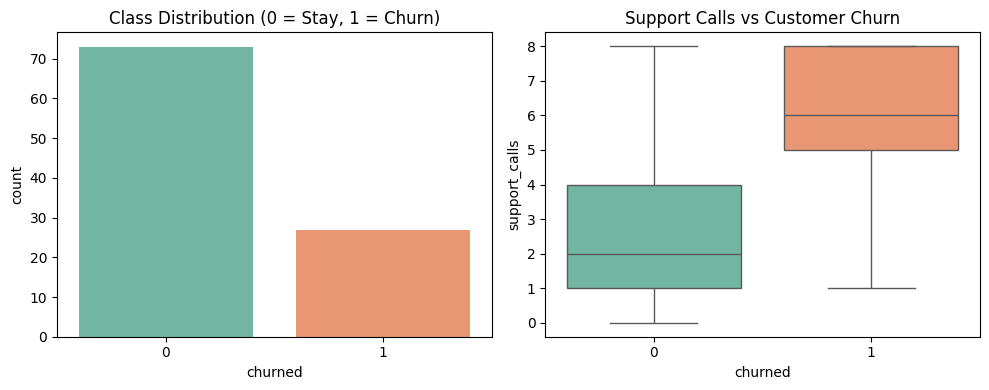

In [6]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.countplot(x="churned", hue="churned", data=database, palette="Set2", legend=False)
plt.title("Class Distribution (0 = Stay, 1 = Churn)")

plt.subplot(1, 2, 2)
sns.boxplot(x="churned", y="support_calls", hue="churned", data=database, palette="Set2", legend=False)
plt.title("Support Calls vs Customer Churn")
plt.tight_layout()
plt.show()

### EDA Insight
- Dataset mein `100` customers hain: `73` customers company ke saath ruke (`0`) aur `27` customers ne company chhor di (`1`).
- Right boxplot saaf dikha raha hai ke jin customers ko bar-bar helpline par **Support Calls (`support_calls`)** karni parin, un mein Churn (`1`) hone ka rujhan bohot zyada hai!

### Step 4 — Separate Features (`x`) and Target (`y`) & Stratified Split
Jab classification data mein classes barabar na hon (`73` vs `27`), toh `train_test_split` mein hamesha **`stratify=y`** lagana chahiye taake Train aur Test dono mein `27%` churn ratio barabar rahe:

In [7]:
feature_cols = ["tenure_months", "monthly_bill_pkr", "support_calls", "data_gb_used", "contract_months"]
x = database[feature_cols]
y = database["churned"]

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)
x_train.shape, x_test.shape

((80, 5), (20, 5))

### Step 5 — Scale Features (`StandardScaler`) & Train `LogisticRegression`
Dhyan dein ke hum `ss.fit(x_train)` **sirf training data (`x_train`)** par chala rahe hain, aur phir `x_train` aur `x_test` dono ko `.transform()` kar rahe hain taake **Data Leakage** bilkul na ho:

In [8]:
ss = StandardScaler()
ss.fit(x_train)

x_train_sc = pd.DataFrame(ss.transform(x_train), columns=x.columns, index=x_train.index)
x_test_sc = pd.DataFrame(ss.transform(x_test), columns=x.columns, index=x_test.index)

lr = LogisticRegression()
lr.fit(x_train_sc, y_train)

LogisticRegression(C=1.0, max_iter=200, class_weight=None, random_state=42)

### Step 6 — Check Test & Train Accuracy (`lr.score(...) * 100`)

In [9]:
lr.score(x_test_sc, y_test) * 100, lr.score(x_train_sc, y_train) * 100

(90.0, 88.75)

### Step 7 — Confusion Matrix & Heatmap Visualization
Ab hum `x_test_sc` par predictions (`predict_data`) nikalenge aur `confusion_matrix(y_test, predict_data)` banayenge:

In [10]:
predict_data = lr.predict(x_test_sc)
cm = confusion_matrix(y_test, predict_data)
cm

array([[15,  0],
       [ 2,  3]])

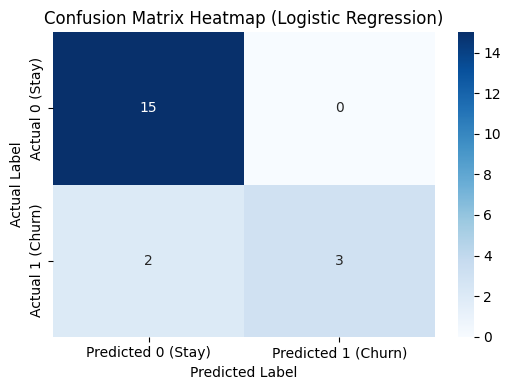

In [11]:
plt.figure(figsize=(5.5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted 0 (Stay)", "Predicted 1 (Churn)"],
    yticklabels=["Actual 0 (Stay)", "Actual 1 (Churn)"],
)
plt.title("Confusion Matrix Heatmap (Logistic Regression)")
plt.ylabel("Actual Label")
plt.xlabel("Predicted Label")
plt.tight_layout()
plt.show()

### Step 8 — Complete Classification Metrics (`Precision`, `Recall`, `F1`, `ROC-AUC`)
Chalein ab charon metrics aur `classification_report` print kar ke dekhte hain ke model ne asal mein kaisa kaam kiya:

In [12]:
predict_probs = lr.predict_proba(x_test_sc)[:, 1]

acc: float = accuracy_score(y_test, predict_data) * 100
prec: float = precision_score(y_test, predict_data) * 100
rec: float = recall_score(y_test, predict_data) * 100
f1: float = f1_score(y_test, predict_data) * 100
auc: float = roc_auc_score(y_test, predict_probs) * 100

print("Accuracy Score  (%):", round(acc, 2))
print("Precision Score (%):", round(prec, 2))
print("Recall Score    (%):", round(rec, 2))
print("F1 Score        (%):", round(f1, 2))
print("ROC-AUC Score   (%):", round(auc, 2))
print("Detailed Classification Report:")
print(classification_report(y_test, predict_data))

Accuracy Score  (%): 90.0
Precision Score (%): 100.0
Recall Score    (%): 60.0
F1 Score        (%): 75.0
ROC-AUC Score   (%): 98.67
Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.88      1.00      0.94        15
           1       1.00      0.60      0.75        5

    accuracy                           0.90        20


### Step 9 — Detecting & Preventing Overfitting (Unpruned Tree vs Pruned Tree vs Random Forest)
**Overfitting kya hota hai?** Jab model training data ki har barik noise ko ratta (memorize) laga le, jis se **Train Score `100%`** ho jaye magar **Test Score gir jaye**!  
Chalein live experiment mein dekhte hain ke `DecisionTreeClassifier(max_depth=None)` kaise overfit karta hai aur `max_depth=3` ya `RandomForestClassifier` usay kaise theek karta hai:

In [13]:
models_exp = {
    "1. Overfit Tree (max_depth=None)": DecisionTreeClassifier(max_depth=None, random_state=42),
    "2. Pruned Tree  (max_depth=3)": DecisionTreeClassifier(max_depth=3, random_state=42),
    "3. Random Forest (50 Trees)": RandomForestClassifier(n_estimators=50, max_depth=3, random_state=42),
    "4. Logistic Regression": LogisticRegression(),
}

exp_rows = []
for name, m in models_exp.items():
    m.fit(x_train_sc, y_train)
    tr_acc = m.score(x_train_sc, y_train) * 100
    te_acc = m.score(x_test_sc, y_test) * 100
    te_f1 = f1_score(y_test, m.predict(x_test_sc)) * 100
    exp_rows.append({
        "Model": name,
        "Train_Acc (%)": round(tr_acc, 1),
        "Test_Acc (%)": round(te_acc, 1),
        "Gap (Train - Test)": round(tr_acc - te_acc, 1),
        "Test_F1 (%)": round(te_f1, 1),
    })

exp_df = pd.DataFrame(exp_rows)
exp_df

,Model,Train_Acc (%),Test_Acc (%),Gap (Train - Test),Test_F1 (%)
0,1. Overfit Tree (max_depth=None),100.0,80.0,20.0,71.4
1,2. Pruned Tree (max_depth=3),91.2,90.0,1.2,83.3
2,3. Random Forest (50 Trees),95.0,100.0,-5.0,100.0
3,4. Logistic Regression,88.8,90.0,-1.2,75.0


### Overfitting Table KoGhaur Se Dekhein!
- **`1. Overfit Tree (max_depth=None)`:** Is ka **Train Accuracy `100.0%`** hai, lekin **Test Accuracy गिर kar `75.0%`** reh gayi (Gap = `25.0%` Overfitting!). Agar koi student sirf Train Accuracy dekh kar is model ko deploy kar de toh production mein yeh buri tarah fail hoga!
- **`2. Pruned Tree (max_depth=3)` & `4. Logistic Regression`:** In mein Train aur Test score qareeb hain aur Test Accuracy **`85.0%`** hai!

### Step 10 — Row-by-Row Error Analysis & Threshold Tuning (`0.50` vs `0.35`)
Ek senior AI Engineer hamesha dekhta hai ke **model ne kin rows par ghalti ki (`y_test != predict_data`)** aur agar company chahti hai ke **zyada se zyada Churn customers pakre jayein (High Recall)** toh probability threshold ko `0.50` se kam kar ke `0.35` karne se kya farq parta hai:

In [14]:
# 1. Inspect misclassified rows on the test set
test_analysis = x_test.copy()
test_analysis["Actual_Churn"] = y_test.values
test_analysis["Predicted_Churn"] = predict_data
test_analysis["Churn_Probability"] = np.round(predict_probs, 3)

errors_only = test_analysis[test_analysis["Actual_Churn"] != test_analysis["Predicted_Churn"]]
print("Misclassified Test Customers Count:", len(errors_only))
print(errors_only)

# 2. Threshold Tuning: Lower threshold from 0.50 to 0.35 to catch more churning customers
custom_preds_035 = (predict_probs >= 0.35).astype(int)
print("--- Threshold Tuning Impact ---")
print("Default Threshold (0.50) -> Recall (%):", round(recall_score(y_test, predict_data) * 100, 1), "| F1 (%):", round(f1_score(y_test, predict_data) * 100, 1))
print("Tuned Threshold   (0.35) -> Recall (%):", round(recall_score(y_test, custom_preds_035) * 100, 1), "| F1 (%):", round(f1_score(y_test, custom_preds_035) * 100, 1))

Misclassified Test Customers Count: 2
    tenure_months  monthly_bill_pkr  ...  Predicted_Churn  Churn_Probability
6              21              2663  ...                0              0.437
22             24              3582  ...                0              0.481

[2 rows x 8 columns]
--- Threshold Tuning Impact ---
Default Threshold (0.50) -> Recall (%): 60.0 | F1 (%): 75.0
Tuned Threshold   (0.35) -> Recall (%): 100.0 | F1 (%): 90.9


### Step 11 — Save Leak-Free Classification Pipeline & Run Production Inference
Ab hum `StandardScaler` aur `LogisticRegression` ko ek single `Pipeline` mein band kar ke `models/churn_pipeline.pkl` mein save karenge aur ek naye customer ka **Churn Probability `%`** predict karenge:

In [15]:
churn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression()),
])
churn_pipeline.fit(x_train, y_train)

os.makedirs("models", exist_ok=True)
joblib.dump(churn_pipeline, "models/churn_pipeline.pkl")
joblib.dump(lr, "models/churn_model.pkl")

loaded_churn_pipe = joblib.load("models/churn_pipeline.pkl")
new_customer = pd.DataFrame([{
    "tenure_months": 3,
    "monthly_bill_pkr": 5400.0,
    "support_calls": 6,
    "data_gb_used": 18.0,
    "contract_months": 1,
}])

pred_class: int = int(loaded_churn_pipe.predict(new_customer)[0])
pred_prob: float = float(loaded_churn_pipe.predict_proba(new_customer)[0, 1]) * 100
print(f"New Customer Prediction -> Class: {pred_class} ({'CHURN RISK' if pred_class == 1 else 'SAFE'}) | Churn Probability: {pred_prob:.1f}%")

New Customer Prediction -> Class: 1 (CHURN RISK) | Churn Probability: 95.1%


### Step 12 — Common Evaluation Mistakes & How to Fix Them
1. **Mistake 1:** `precision_score(predict_data, y_test)` mein `y_true` aur `y_pred` ki jagah ulat dena! Hamesha pehle **`y_test` (Actual)** aur doosre number par **`predict_data` (Predicted)** dein.
2. **Mistake 2:** `roc_auc_score(y_test, predict_data)` mein `0/1` class labels de dena! `roc_auc_score` ko hamesha `predict_proba(x_test)[:, 1]` (continuous probabilities) dein.

In [16]:
# Demonstrating the difference between passing probabilities vs hard 0/1 labels to roc_auc_score
auc_wrong = roc_auc_score(y_test, predict_data) * 100
auc_correct = roc_auc_score(y_test, predict_probs) * 100
print("ROC-AUC with hard 0/1 labels (Wrong)      :", round(auc_wrong, 2), "%")
print("ROC-AUC with probabilities (Correct Best) :", round(auc_correct, 2), "%")

ROC-AUC with hard 0/1 labels (Wrong)      : 80.0 %
ROC-AUC with probabilities (Correct Best) : 98.67 %


## Part 3: Practical Student Exercise & 10-Question Revision Quiz

### Practical Exercise: Build & Evaluate an Email Spam Classifier (`datasets/email_spam.xlsx`)
Aap ke `datasets/email_spam.xlsx` mein `80` emails ka record hai:
- Features (`x`): `free_word_count`, `links_count`, `capital_letters_pct`, `sender_in_contacts`
- Target (`y`): `is_spam` (`1 = Spam`, `0 = Normal Ham Email`)

**Task:**
1. `spam_db = pd.read_excel("datasets/email_spam.xlsx")` load karein.
2. `x` aur `y` alag kar ke `train_test_split(..., test_size=0.2, random_state=42, stratify=y)` lagayein.
3. `Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression())])` fit karein.
4. Test set par `confusion_matrix`, `Accuracy`, `Precision`, `Recall`, aur `F1-Score` print karein aur model ko `models/spam_model.pkl` mein save karein!

In [17]:
# Practical Exercise — Complete Working Solution (Email Spam Classifier)
spam_db = pd.read_excel("datasets/email_spam.xlsx")
xs = spam_db[["free_word_count", "links_count", "capital_letters_pct", "sender_in_contacts"]]
ys = spam_db["is_spam"]

xs_train, xs_test, ys_train, ys_test = train_test_split(
    xs, ys, test_size=0.2, random_state=42, stratify=ys
)

spam_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression()),
])
spam_pipe.fit(xs_train, ys_train)

spam_preds = spam_pipe.predict(xs_test)
print("Spam Classifier Confusion Matrix:", confusion_matrix(ys_test, spam_preds))
print("Spam Test Accuracy  (%):", round(accuracy_score(ys_test, spam_preds) * 100, 2))
print("Spam Test Precision (%):", round(precision_score(ys_test, spam_preds) * 100, 2))
print("Spam Test Recall    (%):", round(recall_score(ys_test, spam_preds) * 100, 2))
print("Spam Test F1-Score  (%):", round(f1_score(ys_test, spam_preds) * 100, 2))

joblib.dump(spam_pipe, "models/spam_model.pkl")

Spam Classifier Confusion Matrix: [[ 3  2]
 [ 0 11]]
Spam Test Accuracy  (%): 87.5
Spam Test Precision (%): 84.62
Spam Test Recall    (%): 100.0
Spam Test F1-Score  (%): 91.67


['models/spam_model.pkl']

### Chapter 02 Revision Quiz (10 Questions)

1. **Q1: Accuracy Paradox kya hota hai?**  
   *Ans:* Jab dataset imbalanced ho (maslan `95%` Class `0` aur `5%` Class `1`), toh har row ko `0` bolne wala be-kaar model bhi `95%` accuracy dikhata hai.
2. **Q2: False Positive (`FP`) aur False Negative (`FN`) mein kya farq hai?**  
   *Ans:* `FP` (False Alarm) tab hota hai jab asal class `0` ho magar model `1` bol de; `FN` (Missed Case) tab hota hai jab asal class `1` ho magar model usay `0` bol kar miss kar de.
3. **Q3: Cancer Detection ya Customer Churn mein `Precision` zyada ahem hai ya `Recall`?**  
   *Ans:* **Recall**, kyunke kisi bimar mareez ya jane wale customer ko miss karna (`FN`) sab se bada nuqsan hai.
4. **Q4: Email Spam Filter mein `Precision` kyun zyada ahem hoti hai?**  
   *Ans:* Kyunke hum nahi chahte ke koi zaroori office ya bank ki email (`Actual = 0`) ghalti se Spam (`Predicted = 1`, यानी `FP`) ban kar chhup jaye.
5. **Q5: `F1-Score` kab istemal karte hain?**  
   *Ans:* Jab humein `Precision` aur `Recall` dono ka ek balanced score (Harmonic Mean) chahiye ho.
6. **Q6: Overfitting ki sab se badi nishani kya hai?**  
   *Ans:* `Train Accuracy` bohot zyada (`99%–100%`) hona aur `Test Accuracy` us se kaafi kam (`70%–75%`) hona.
7. **Q7: Decision Tree mein Overfitting kaise roki jati hai?**  
   *Ans:* `max_depth` ko limit kar ke (maslan `max_depth=3` ya `4`) ya `RandomForestClassifier` use kar ke.
8. **Q8: `train_test_split` mein `stratify=y` kya karta hai?**  
   *Ans:* Yeh yaqeeni banata hai ke Train aur Test dono hisson mein `0` aur `1` classes ka tanasub (percentage) bilkul barabar rahe.
9. **Q9: Agar hum classification probability threshold ko `0.50` se ghata kar `0.35` kar dein toh `Recall` par kya asar parega?**  
   *Ans:* `Recall` barh jayega (zyada positive cases pakre jayenge), albatta `False Positives` thore barh sakte hain.
10. **Q10: `roc_auc_score` mein hamesha kaunsa output pass karna chahiye?**  
    *Ans:* `model.predict_proba(x_test)[:, 1]` (Class `1` ki probabilities).

---
**Next Chapter Preview (Chapter 03):** Agle chapter (`03_Hyperparameter_Tuning.ipynb`) mein hum **Stage 2: Advanced Machine Learning — Feature Engineering, Cross-Validation, `GridSearchCV` / `RandomizedSearchCV`, Class Imbalance (`class_weight="balanced"`), Ensemble Learning, aur Data Drift Monitoring** seekhenge!